In [13]:
%pip install pandas
%pip install scikit-learn statsmodels
%pip install matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [14]:
import sys
from pathlib import Path
import pandas as pd

# Project root
PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

# Project modules
from data_loader import load_and_split_aemo

from drift_lab.forecasters import (
    SeasonalNaiveForecaster,
    SARIMAXForecaster,
    GradientBoostedForecaster,
    frozen_error_stream,
)

from drift_lab.evaluation import (
    calculate_mae,
    calculate_rolling_mae,
)

from drift_lab.run_logger import (
    ensure_runs_file,
    log_run,
)

print("Imports successful.")
print("Project root:", PROJECT_ROOT)

Imports successful.
Project root: /workspaces/Detecting-and-Adapting-to-Concept-Drift-in-Time-Series-Forecasting


In [15]:
def run_region_baselines(region):
    """
    Run all three frozen baseline forecasters for one region.

    Returns
    -------
    dict
        One error-stream DataFrame per forecasting method.
    """

    data, train, calibration, test = load_and_split_aemo(
        region=region,
        data_path=PROJECT_ROOT / "data" / "raw"
    )

    models = {
        "Seasonal Naive": SeasonalNaiveForecaster(
            season=48
        ),
        "SARIMAX": SARIMAXForecaster(),
        "Gradient Boosted": GradientBoostedForecaster(
            feature_mode="calendar+lags",
            lags=(48, 336),
            seed=0
        ),
    }

    streams = {}

    for method, model in models.items():

        model.fit(train)

        stream = frozen_error_stream(
            model,
            test,
            history_df=calibration
        )

        stream["rolling_mae"] = calculate_rolling_mae(
            stream["y_true"],
            stream["y_pred"]
        ).to_numpy()

        streams[method] = stream

        mae = calculate_mae(
            stream["y_true"],
            stream["y_pred"]
        )

        print(
            f"{region} | {method}: "
            f"MAE={mae:.2f} MW, "
            f"rows={len(stream)}, "
            f"rolling NaNs="
            f"{stream['rolling_mae'].isna().sum()}"
        )

    return streams

In [12]:
sa1_streams = run_region_baselines("SA1")

SA1 | Seasonal Naive: MAE=155.87 MW, rows=67249, rolling NaNs=335
SA1 | SARIMAX: MAE=43.00 MW, rows=67249, rolling NaNs=335
SA1 | Gradient Boosted: MAE=147.29 MW, rows=67249, rolling NaNs=335


In [16]:
nsw1_streams = run_region_baselines("NSW1")


NSW1 | Seasonal Naive: MAE=442.27 MW, rows=67249, rolling NaNs=335
NSW1 | SARIMAX: MAE=122.86 MW, rows=67249, rolling NaNs=335
NSW1 | Gradient Boosted: MAE=372.57 MW, rows=67249, rolling NaNs=335


In [17]:
# Start with an empty list
all_predictions = []


region_results = {
    "SA1": sa1_streams,
    "NSW1": nsw1_streams,
}

for region, region_streams in region_results.items():

    for method, stream in region_streams.items():

        temp = stream.copy()

        temp["region"] = region
        temp["method"] = method

        all_predictions.append(temp)


# Combine everything
all_predictions = pd.concat(
    all_predictions,
    ignore_index=True
)


# Keep columns in a consistent order
all_predictions = all_predictions[
    [
        "SETTLEMENTDATE",
        "region",
        "method",
        "y_true",
        "y_pred",
        "error",
        "rolling_mae",
    ]
]


print("Shape:", all_predictions.shape)

print("\nRows per region and method:")
print(
    all_predictions
    .groupby(["region", "method"])
    .size()
)

print("\nPreview:")
print(all_predictions.head())

Shape: (403494, 7)

Rows per region and method:
region  method          
NSW1    Gradient Boosted    67249
        SARIMAX             67249
        Seasonal Naive      67249
SA1     Gradient Boosted    67249
        SARIMAX             67249
        Seasonal Naive      67249
dtype: int64

Preview:
       SETTLEMENTDATE region          method   y_true   y_pred  error  \
0 2020-03-01 00:00:00    SA1  Seasonal Naive  1377.68  1412.56 -34.88   
1 2020-03-01 00:30:00    SA1  Seasonal Naive  1330.34  1365.10 -34.76   
2 2020-03-01 01:00:00    SA1  Seasonal Naive  1261.70  1305.29 -43.59   
3 2020-03-01 01:30:00    SA1  Seasonal Naive  1182.48  1230.98 -48.50   
4 2020-03-01 02:00:00    SA1  Seasonal Naive  1129.30  1193.63 -64.33   

   rolling_mae  
0          NaN  
1          NaN  
2          NaN  
3          NaN  
4          NaN  


#### Documented Events Used in the SA1 F1 Degradation Curve

The following AEMO-documented events are included as historical reference
points when interpreting changes in rolling forecasting error. These
annotations provide context only and are not treated as ground-truth concept
drift events.

- **March–April 2020 — COVID-19 Disruption Period:**  
  AEMO reported that changes in work, education, business activity and daily
  routines during the early COVID-19 period affected electricity-demand
  behaviour across Australia. AEMO also noted that separating the COVID-19
  effect from weather, seasonality, day-of-week effects and rooftop PV was
  challenging. This period is therefore included as broader historical
  context rather than as a confirmed SA1-specific drift event.

- **14 March 2021 — SA Minimum Operational Demand Intervention:**  
  South Australian operational demand fell to 358 MW during conditions of
  mild weather, low underlying demand and high distributed PV generation.
  AEMO instructed ElectraNet to maintain operational demand above 400 MW,
  resulting in approximately 71 MW of distributed PV curtailment. AEMO's
  subsequent review identified under-forecast distributed PV generation,
  over-forecast industrial load and variable cloud cover as factors that
  made operational-demand forecasting challenging during the event.

- **22 July 2021 — SA Record-High Winter Maximum Demand:**  
  South Australia recorded a new record-high winter maximum demand on
  22 July 2021. AEMO reported that this was the third consecutive year in
  which South Australia set a new winter maximum-demand record. The event
  occurred during unusually cold conditions, and AEMO noted that the
  continuing increase in winter maximum demand warranted further analysis.

- **1 October 2021 — Five-Minute Settlement (5MS) Commencement:**  
  Five-Minute Settlement commenced across the National Electricity Market
  on 1 October 2021, aligning operational dispatch and financial settlement
  at five-minute intervals. The event is included as a major market and
  settlement change occurring during the evaluation period.

- **21 November 2021 — SA Record Minimum Operational Demand / High Rooftop PV:**  
  South Australia recorded a then-record minimum operational demand of
  104 MW on 21 November 2021. Estimated rooftop PV output was approximately
  1,220 MW and supplied about 92% of the region's underlying electricity
  demand during the relevant half-hour. This provides an SA-specific
  reference point associated with very high rooftop-PV penetration and
  exceptionally low operational demand.

- **15–24 June 2022 — NEM Spot-Market Suspension:**  
  AEMO suspended the NEM spot market on 15 June 2022 during exceptional
  market and operational conditions. The suspension ended on 24 June 2022,
  when the spot market resumed across all NEM regions.

- **7 January–25 February 2023 — SA System-Security Directions:**  
  AEMO issued a series of directions to South Australian market participants
  to maintain power-system security. AEMO documents consecutive direction
  periods from 7–28 January 2023 and 29 January–25 February 2023; these are
  represented in F1 as one continuous contextual window.

#### References

1. Australian Energy Market Operator (AEMO), *COVID-19 demand impact in Australia*, 28 April 2020.  
   https://aemo.com.au/newsroom/news-updates/demand-impact-australia-covid19

2. Australian Energy Market Operator (AEMO), *Maintaining operational demand in South Australia on 14 March 2021*.  
   https://www.aemo.com.au/-/media/files/electricity/nem/market_notices_and_events/power_system_incident_reports/2021/maintaining-operational-demand-in-south-australia.pdf

3. Australian Energy Market Operator (AEMO), *Forecast Accuracy Report 2021*.  
   https://www.aemo.com.au/-/media/files/electricity/nem/planning_and_forecasting/accuracy-report/forecast-accuracy-report-2021.pdf

4. Australian Energy Market Operator (AEMO), *5MS Commencement*.  
   https://www.aemo.com.au/initiatives/major-programs/past-major-programs/five-minute-settlement/5ms-program-management/5ms-commencement

5. Australian Energy Market Operator (AEMO), *Negative electricity demand in South Australia*, 23 November 2021.  
   https://www.aemo.com.au/newsroom/news-updates/negative-electricity-demand-in-south-australia

6. Australian Energy Market Operator (AEMO), *NEM market suspension and operational challenges in June 2022*.  
   https://www.aemo.com.au/-/media/files/electricity/nem/market_notices_and_events/market_event_reports/2022/nem-market-suspension-and-operational-challenges-in-june-2022.pdf

7. Australian Energy Market Operator (AEMO), *Directions to SA generators — 7 January 2023 to 28 January 2023*.  
   https://www.aemo.com.au/energy-systems/electricity/national-electricity-market-nem/nem-events-and-reports/market-event-reports/directions-to-sa-generators---7-january-2023-to-28-january-2023

8. Australian Energy Market Operator (AEMO), *Directions to SA generators — 29 January 2023 to 25 February 2023*.  
   https://www.aemo.com.au/energy-systems/electricity/national-electricity-market-nem/nem-events-and-reports/market-event-reports/directions-to-sa-generators---29-january-2023-to-25-february-2023

#### Interpretation Note

The documented events are used only as historical context for interpreting
changes in forecasting performance. Temporal proximity or overlap between an
event and an increase in rolling MAE does not establish that the event caused
the forecasting degradation or that concept drift occurred. Formal drift
detection is evaluated separately.

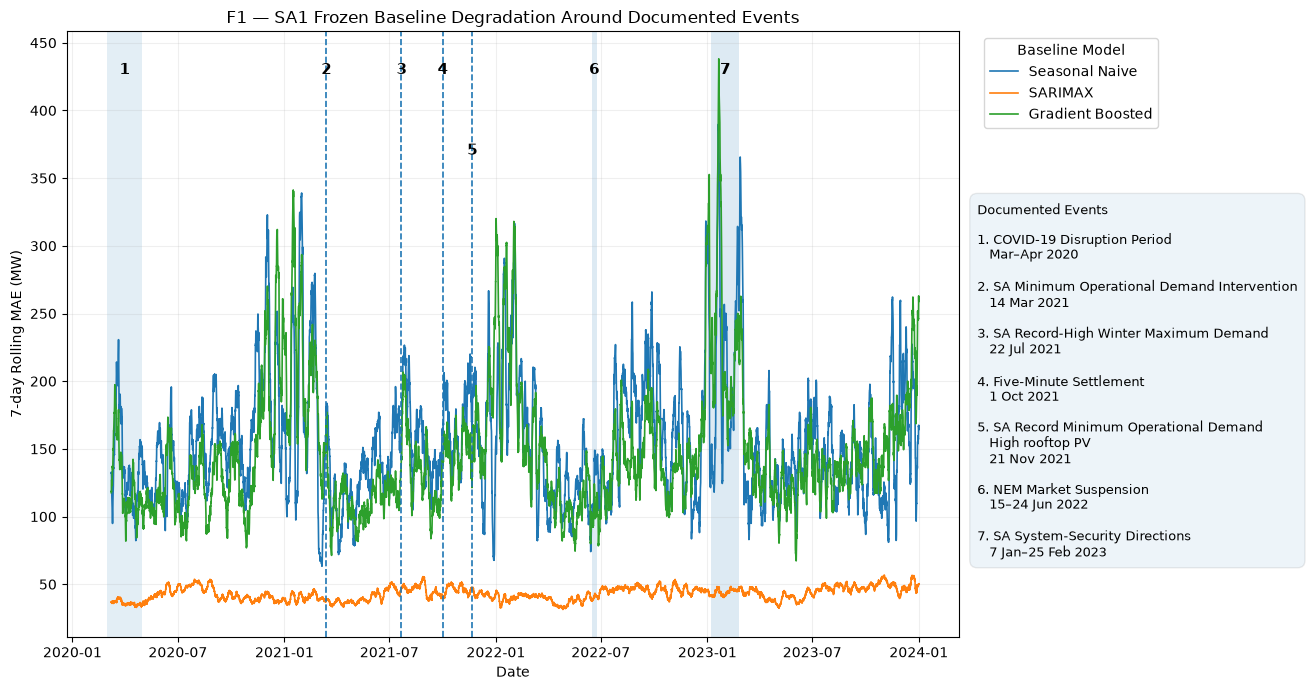

In [28]:
import matplotlib.pyplot as plt
import pandas as pd

# Select SA1 results
sa1_plot = all_predictions[
    all_predictions["region"] == "SA1"
]

fig, ax = plt.subplots(figsize=(17, 7))

# Plot rolling MAE for each frozen baseline
for method in [
    "Seasonal Naive",
    "SARIMAX",
    "Gradient Boosted"
]:
    subset = sa1_plot[
        sa1_plot["method"] == method
    ]

    ax.plot(
        subset["SETTLEMENTDATE"],
        subset["rolling_mae"],
        label=method,
        linewidth=1.2
    )


# Event 1: COVID-19 disruption period
covid_start = pd.Timestamp("2020-03-01")
covid_end = pd.Timestamp("2020-04-30")

ax.axvspan(
    covid_start,
    covid_end,
    alpha=0.12
)

ax.text(
    covid_start + (covid_end - covid_start) / 2,
    ax.get_ylim()[1] * 0.95,
    "1",
    ha="center",
    va="top",
    fontweight="bold",
    fontsize=11
)


# Event 2: SA minimum operational demand intervention
minimum_demand_event = pd.Timestamp("2021-03-14")

ax.axvline(
    minimum_demand_event,
    linestyle="--",
    linewidth=1.2
)

ax.text(
    minimum_demand_event,
    ax.get_ylim()[1] * 0.95,
    "2",
    ha="center",
    va="top",
    fontweight="bold",
    fontsize=11
)


# Event 3: SA record-high winter maximum demand
winter_demand_event = pd.Timestamp("2021-07-22")

ax.axvline(
    winter_demand_event,
    linestyle="--",
    linewidth=1.2
)

ax.text(
    winter_demand_event,
    ax.get_ylim()[1] * 0.95,
    "3",
    ha="center",
    va="top",
    fontweight="bold",
    fontsize=11
)


# Event 4: Five-Minute Settlement
five_minute_settlement = pd.Timestamp("2021-10-01")

ax.axvline(
    five_minute_settlement,
    linestyle="--",
    linewidth=1.2
)

ax.text(
    five_minute_settlement,
    ax.get_ylim()[1] * 0.95,
    "4",
    ha="center",
    va="top",
    fontweight="bold",
    fontsize=11
)


# Event 5: SA record minimum operational demand
solar_event = pd.Timestamp("2021-11-21")

ax.axvline(
    solar_event,
    linestyle="--",
    linewidth=1.2
)

ax.text(
    solar_event,
    ax.get_ylim()[1] * 0.82,
    "5",
    ha="center",
    va="top",
    fontweight="bold",
    fontsize=11
)


# Event 6: NEM Market Suspension
suspension_start = pd.Timestamp("2022-06-15")
suspension_end = pd.Timestamp("2022-06-24")

ax.axvspan(
    suspension_start,
    suspension_end,
    alpha=0.15
)

ax.text(
    suspension_start + (suspension_end - suspension_start) / 2,
    ax.get_ylim()[1] * 0.95,
    "6",
    ha="center",
    va="top",
    fontweight="bold",
    fontsize=11
)


# Event 7: SA system-security directions
security_start = pd.Timestamp("2023-01-07")
security_end = pd.Timestamp("2023-02-25")

ax.axvspan(
    security_start,
    security_end,
    alpha=0.15
)

ax.text(
    security_start + (security_end - security_start) / 2,
    ax.get_ylim()[1] * 0.95,
    "7",
    ha="center",
    va="top",
    fontweight="bold",
    fontsize=11
)


# Figure formatting
ax.set_title(
    "F1 — SA1 Frozen Baseline Degradation Around Documented Events"
)

ax.set_xlabel("Date")
ax.set_ylabel("7-day Rolling MAE (MW)")
ax.grid(alpha=0.2)

ax.legend(
    title="Baseline Model",
    loc="upper left",
    bbox_to_anchor=(1.02, 1.00)
)

event_text = (
    "Documented Events\n\n"
    "1. COVID-19 Disruption Period\n"
    "   Mar–Apr 2020\n\n"
    "2. SA Minimum Operational Demand Intervention\n"
    "   14 Mar 2021\n\n"
    "3. SA Record-High Winter Maximum Demand\n"
    "   22 Jul 2021\n\n"
    "4. Five-Minute Settlement\n"
    "   1 Oct 2021\n\n"
    "5. SA Record Minimum Operational Demand\n"
    "   High rooftop PV\n"
    "   21 Nov 2021\n\n"
    "6. NEM Market Suspension\n"
    "   15–24 Jun 2022\n\n"
    "7. SA System-Security Directions\n"
    "   7 Jan–25 Feb 2023"
)

ax.text(
    1.02,
    0.72,
    event_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9,
    linespacing=1.25,
    bbox=dict(
        boxstyle="round,pad=0.6",
        alpha=0.08
    )
)

plt.tight_layout(
    rect=[0, 0, 0.78, 1]
)

plt.show()

In SA1, SARIMAX shows lower and comparatively stable rolling MAE, while Seasonal Naive and Gradient Boosted show larger periods of elevated forecasting error.

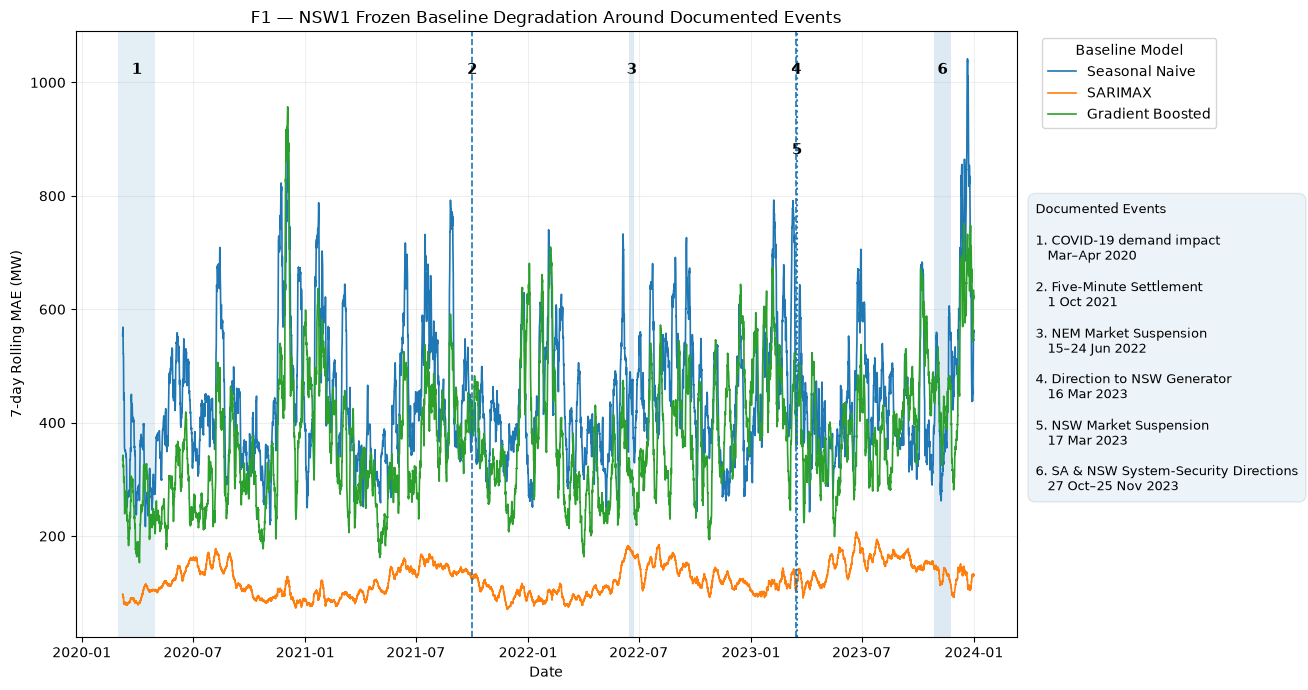

In [29]:
import matplotlib.pyplot as plt
import pandas as pd

# Select NSW1 results
nsw1_plot = all_predictions[
    all_predictions["region"] == "NSW1"
]

fig, ax = plt.subplots(figsize=(17, 7))

# Plot rolling MAE for each frozen baseline
for method in [
    "Seasonal Naive",
    "SARIMAX",
    "Gradient Boosted"
]:
    subset = nsw1_plot[
        nsw1_plot["method"] == method
    ]

    ax.plot(
        subset["SETTLEMENTDATE"],
        subset["rolling_mae"],
        label=method,
        linewidth=1.2
    )



# Event 1: COVID-19 demand impact
covid_start = pd.Timestamp("2020-03-01")
covid_end = pd.Timestamp("2020-04-30")

ax.axvspan(
    covid_start,
    covid_end,
    alpha=0.12
)

ax.text(
    covid_start + (covid_end - covid_start) / 2,
    ax.get_ylim()[1] * 0.95,
    "1",
    ha="center",
    va="top",
    fontweight="bold",
    fontsize=11
)



# Event 2: Five-Minute Settlement
five_minute_settlement = pd.Timestamp("2021-10-01")

ax.axvline(
    five_minute_settlement,
    linestyle="--",
    linewidth=1.2
)

ax.text(
    five_minute_settlement,
    ax.get_ylim()[1] * 0.95,
    "2",
    ha="center",
    va="top",
    fontweight="bold",
    fontsize=11
)



# Event 3: NEM Market Suspension
suspension_start = pd.Timestamp("2022-06-15")
suspension_end = pd.Timestamp("2022-06-24")

ax.axvspan(
    suspension_start,
    suspension_end,
    alpha=0.15
)

ax.text(
    suspension_start + (suspension_end - suspension_start) / 2,
    ax.get_ylim()[1] * 0.95,
    "3",
    ha="center",
    va="top",
    fontweight="bold",
    fontsize=11
)



# Event 4: NSW generator direction
nsw_direction = pd.Timestamp("2023-03-16")

ax.axvline(
    nsw_direction,
    linestyle="--",
    linewidth=1.2
)

ax.text(
    nsw_direction,
    ax.get_ylim()[1] * 0.95,
    "4",
    ha="center",
    va="top",
    fontweight="bold",
    fontsize=11
)



# Event 5: NSW Market Suspension
nsw_market_suspension = pd.Timestamp("2023-03-17")

ax.axvline(
    nsw_market_suspension,
    linestyle=":",
    linewidth=1.5
)

ax.text(
    nsw_market_suspension,
    ax.get_ylim()[1] * 0.82,
    "5",
    ha="center",
    va="top",
    fontweight="bold",
    fontsize=11
)



# Event 6: SA & NSW system-security directions
security_start = pd.Timestamp("2023-10-27")
security_end = pd.Timestamp("2023-11-25")

ax.axvspan(
    security_start,
    security_end,
    alpha=0.15
)

ax.text(
    security_start + (security_end - security_start) / 2,
    ax.get_ylim()[1] * 0.95,
    "6",
    ha="center",
    va="top",
    fontweight="bold",
    fontsize=11
)



# Figure formatting
ax.set_title(
    "F1 — NSW1 Frozen Baseline Degradation Around Documented Events"
)

ax.set_xlabel("Date")
ax.set_ylabel("7-day Rolling MAE (MW)")

ax.grid(alpha=0.2)

# Legend outside the chart
ax.legend(
    title="Baseline Model",
    loc="upper left",
    bbox_to_anchor=(1.02, 1.00)
)

# Event descriptions outside the chart
event_text = (
    "Documented Events\n\n"
    "1. COVID-19 demand impact\n"
    "   Mar–Apr 2020\n\n"
    "2. Five-Minute Settlement\n"
    "   1 Oct 2021\n\n"
    "3. NEM Market Suspension\n"
    "   15–24 Jun 2022\n\n"
    "4. Direction to NSW Generator\n"
    "   16 Mar 2023\n\n"
    "5. NSW Market Suspension\n"
    "   17 Mar 2023\n\n"
    "6. SA & NSW System-Security Directions\n"
    "   27 Oct–25 Nov 2023"
)

ax.text(
    1.02,
    0.72,
    event_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=9,
    bbox=dict(
        boxstyle="round,pad=0.6",
        alpha=0.08
    )
)

# Leave room on the right
plt.tight_layout(
    rect=[0, 0, 0.78, 1]
)

plt.show()

In [18]:
# Path for the required shared results file
RUNS_PATH = PROJECT_ROOT / "results" / "runs.csv"

# Create the results file with the required schema
# if it does not already exist
ensure_runs_file(
    results_path=RUNS_PATH
)

print("runs.csv ready at:")
print(RUNS_PATH)

runs.csv ready at:
/workspaces/Detecting-and-Adapting-to-Concept-Drift-in-Time-Series-Forecasting/results/runs.csv


In [ ]:
# Regime boundaries are not defined explicitly in the required-output document.
# Do not log MAE to runs.csv until the team agrees on the exact windows.

REGIME_WINDOWS = {
    "pre-drift": None,
    "drift": None,
    "post-drift": None,
}

print(REGIME_WINDOWS)

In [19]:
# Calculate overall MAE for every region × model combination
baseline_mae_summary = (
    all_predictions
    .groupby(["region", "method"])
    .apply(
        lambda x: calculate_mae(
            x["y_true"],
            x["y_pred"]
        ),
        include_groups=False
    )
    .reset_index(name="MAE")
)

print(baseline_mae_summary)

  region            method         MAE
0   NSW1  Gradient Boosted  372.569365
1   NSW1           SARIMAX  122.861038
2   NSW1    Seasonal Naive  442.266502
3    SA1  Gradient Boosted  147.293096
4    SA1           SARIMAX   43.002919
5    SA1    Seasonal Naive  155.865317
